# Parcoursup 2023 : égalité d'accès selon le profil et le territoire

**Problématique :** à candidature égale, Parcoursup favorise-t-il les candidats dont le bac correspond à la filière visée ? Les quotas (bacs pro en BTS, bacs techno en BUT, boursiers) modifient-ils ces écarts, et sont-ils appliqués de façon homogène sur le territoire ?

Ce notebook contient l'analyse exploratoire :
1. chargement et préparation des données ;
2. l'entonnoir candidats → classés → propositions → admis ;
3. le ratio de représentation `R` par filière et les tests du χ² ;
4. les formations où les bacheliers généraux sont désavantagés ;
5. la dimension géographique (régions, zones, recrutement local) ;
6. les cartes.

**Indicateur central :** `R = part du profil dans les propositions / part du profil dans les candidats`.
R = 1 : égalité ; R < 1 : profil désavantagé ; R > 1 : profil favorisé.

## 1. Chargement et préparation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import plotly.express as px
from scipy.stats import chi2_contingency

pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("fr-esr-parcoursup_2023.csv")
GEOJSON = Path("data/regions.geojson")

MIN_CANDIDATS = 5          # effectif minimal d'un profil pour calculer R sur une formation
MIN_FORMATIONS_REGION = 15  # nombre minimal de formations pour afficher une région

PROFILS = ["G", "T", "P", "B"]
NOMS_PROFILS = {"G": "Bac général", "T": "Bac techno", "P": "Bac pro", "B": "Boursiers"}

In [2]:
raw = pd.read_csv(DATA, sep=";", encoding="utf-8-sig", low_memory=False)
print(f"{raw.shape[0]} formations, {raw.shape[1]} colonnes")

# Plusieurs colonnes ont des noms très longs ou en double : on les sélectionne par position
# et on leur donne des noms courts. Les positions sont vérifiées par un extrait du libellé.
COLONNES = {
    1: ("statut", "Statut de l"),
    3: ("etablissement", "Établissement"),
    6: ("region", "Région de l"),
    7: ("academie", "Académie de l"),
    8: ("commune", "Commune de l"),
    10: ("selectivite", "Sélectivité"),
    11: ("filiere", "Filière de formation très agrégée"),
    14: ("specialite", "Filière de formation détaillée bis"),
    16: ("gps", "Coordonnées GPS"),
    17: ("capacite", "Capacité de l"),
    20: ("cand_total", "Effectif total des candidats en phase principale"),
    # candidats néo-bacheliers en phase principale
    22: ("cand_G", "néo bacheliers généraux en phase principale"),
    23: ("cand_BG", "boursiers néo bacheliers généraux en phase principale"),
    24: ("cand_T", "néo bacheliers technologiques en phase principale"),
    25: ("cand_BT", "boursiers néo bacheliers technologiques en phase principale"),
    26: ("cand_P", "néo bacheliers professionnels en phase principale"),
    27: ("cand_BP", "boursiers néo bacheliers professionnels en phase principale"),
    # candidats classés par l'établissement
    38: ("clas_G", "néo bacheliers généraux classés"),
    39: ("clas_BG", "boursiers néo bacheliers généraux classés"),
    40: ("clas_T", "néo bacheliers technologiques classés"),
    41: ("clas_BT", "boursiers néo bacheliers technologiques classés"),
    42: ("clas_P", "néo bacheliers professionnels classés"),
    43: ("clas_BP", "boursiers néo bacheliers professionnels classés"),
    # propositions d'admission (candidats en terminale)
    94: ("prop_G", "terminale générale ayant reçu"),
    95: ("prop_BG", "boursiers en terminale générale ayant reçu"),
    96: ("prop_T", "terminale technologique ayant reçu"),
    97: ("prop_BT", "boursiers en terminale technologique ayant reçu"),
    98: ("prop_P", "terminale professionnelle ayant reçu"),
    99: ("prop_BP", "boursiers en terminale générale professionnelle"),
    # admis
    54: ("adm_B", "admis boursiers néo bacheliers"),
    55: ("adm_neo", "Effectif des admis néo bacheliers"),
    56: ("adm_G", "admis néo bacheliers généraux"),
    57: ("adm_T", "admis néo bacheliers technologiques"),
    58: ("adm_P", "admis néo bacheliers professionnels"),
    71: ("adm_meme_acad", "issus de la même académie"),
    72: ("adm_meme_acad_idf", "Paris/Créteil/Versailles réunies"),
    112: ("taux_acces", "Taux d"),
}

for pos, (_, extrait) in COLONNES.items():
    assert extrait in raw.columns[pos], f"colonne {pos} inattendue : {raw.columns[pos]!r}"

df = raw.iloc[:, list(COLONNES)].copy()
df.columns = [nom for nom, _ in COLONNES.values()]

# Les boursiers sont la somme des trois types de bac
for etape in ["cand", "clas", "prop"]:
    df[f"{etape}_B"] = df[[f"{etape}_BG", f"{etape}_BT", f"{etape}_BP"]].sum(axis=1)

# Normalisation des noms de régions (pour la jointure avec la carte)
df["region"] = df["region"].replace({
    "Ile-de-France": "Île-de-France",
    "Provence Alpes Côte d'Azur": "Provence-Alpes-Côte d'Azur",
})

DROM = {"Guadeloupe", "Martinique", "Guyane", "La Réunion", "Mayotte"}
def zone(region):
    if region == "Île-de-France":
        return "Île-de-France"
    if region in DROM:
        return "Outre-mer (DROM)"
    if region in {"Etranger", "Polynésie française", "Saint-Martin"}:
        return "Autre"
    return "Province"
df["zone"] = df["region"].map(zone)

# Coordonnées GPS "lat, lon"
gps = df["gps"].str.split(",", expand=True)
df["lat"] = pd.to_numeric(gps[0], errors="coerce")
df["lon"] = pd.to_numeric(gps[1], errors="coerce")

df[["etablissement", "filiere", "region", "zone", "cand_G", "cand_T", "cand_P", "cand_B", "prop_G", "prop_T", "prop_P", "prop_B"]].head()

13869 formations, 118 colonnes


,etablissement,filiere,region,zone,cand_G,cand_T,cand_P,cand_B,prop_G,prop_T,prop_P,prop_B
0,Facultés libres de l'ouest - UCO - Bretagne Sud,Licence,Bretagne,Province,255,69,5,37,236.0,53.0,3.0,36.0
1,Université de Bretagne Sud - Site de Lorient,Licence,Bretagne,Province,184,164,23,78,190.0,139.0,28.0,85.0
2,Université de Bretagne Sud - Site de Lorient,Licence_Las,Bretagne,Province,141,97,22,51,93.0,22.0,3.0,24.0
3,Université de Bretagne Sud - Site de Lorient,Licence,Bretagne,Province,195,13,1,21,127.0,2.0,2.0,12.0
4,Université de Bretagne Sud - Site de Lorient,Licence,Bretagne,Province,148,40,7,28,79.0,24.0,4.0,21.0


In [3]:
# Contrôle qualité rapide
compte_cols = [c for c in df.columns if c.startswith(("cand_", "clas_", "prop_", "adm_"))]
print("Valeurs manquantes dans les effectifs :", int(df[compte_cols].isna().sum().sum()))
print("Formations sans coordonnées GPS :", int(df["lat"].isna().sum()))
print()
print(df["filiere"].value_counts().to_string())

Valeurs manquantes dans les effectifs : 0
Formations sans coordonnées GPS : 90

filiere
BTS                  5339
Licence              2903
Autre formation      1749
CPGE                  983
BUT                   816
Licence_Las           550
Ecole d'Ingénieur     472
IFSI                  340
PASS                  278
EFTS                  231
Ecole de Commerce     208


## 2. L'entonnoir de sélection

Pour chaque profil, on suit sa part à chaque étape : **candidats → classés → propositions → admis**.

On mesure la sélection entre *candidats* et *propositions*. La dernière étape (admis) dépend aussi du choix du candidat d'accepter ou non, elle n'est montrée qu'à titre indicatif.

In [4]:
ETAPES = {"cand": "Candidats", "clas": "Classés", "prop": "Propositions"}

def parts(data, etape):
    # Part de chaque profil à une étape (les boursiers sont rapportés au total des 3 bacs)
    eff = data[[f"{etape}_{p}" for p in PROFILS]].sum()
    total = eff[[f"{etape}_G", f"{etape}_T", f"{etape}_P"]].sum()
    return pd.Series((eff / total).values * 100, index=PROFILS)

def entonnoir(data):
    t = pd.DataFrame({nom: parts(data, e) for e, nom in ETAPES.items()})
    adm = data[["adm_G", "adm_T", "adm_P", "adm_B"]].sum()
    t["Admis"] = (adm / adm[["adm_G", "adm_T", "adm_P"]].sum()).values * 100
    t.index = [NOMS_PROFILS[p] for p in PROFILS]
    return t

entonnoir(df).round(1)

,Candidats,Classés,Propositions,Admis
Bac général,72.5,75.1,75.8,69.5
Bac techno,18.7,17.1,16.4,19.2
Bac pro,8.8,7.8,7.8,11.3
Boursiers,21.0,19.8,20.2,23.8


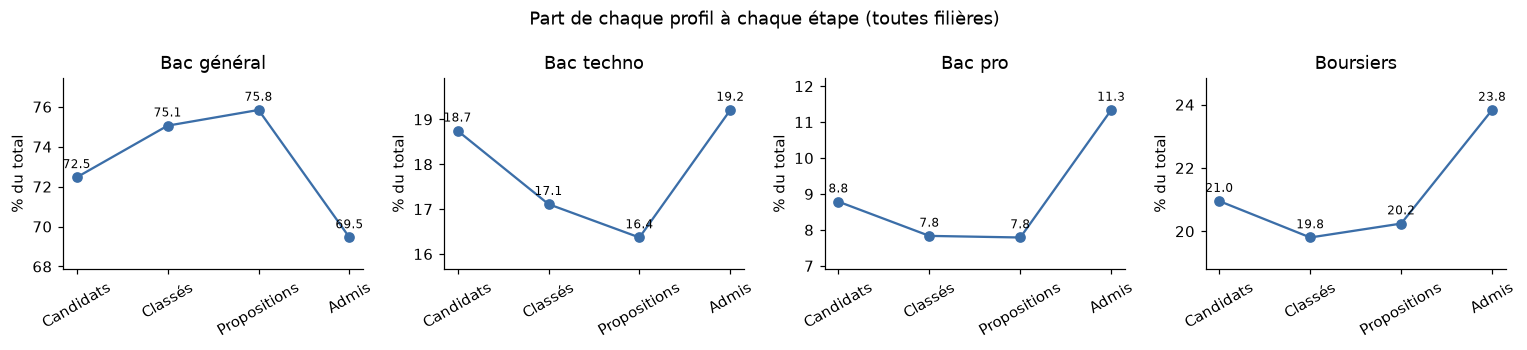

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=False)
ent = entonnoir(df)
for ax, (profil, ligne) in zip(axes, ent.iterrows()):
    ax.plot(ligne.index, ligne.values, marker="o", color="#3b6ea8")
    ax.set_title(profil)
    ax.margins(y=0.25)
    ax.set_ylabel("% du total")
    ax.tick_params(axis="x", rotation=30)
    for x, y in zip(ligne.index, ligne.values):
        ax.annotate(f"{y:.1f}", (x, y), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
fig.suptitle("Part de chaque profil à chaque étape (toutes filières)")
fig.tight_layout()

## 3. Ratio de représentation `R` par filière

`R` est calculé sur les effectifs cumulés du groupe (pas comme une moyenne des ratios des formations), ce qui évite que les petites formations pèsent autant que les grandes.

In [6]:
def ratio_R(data):
    # R pour chaque profil, calculé sur les effectifs cumulés
    return (parts(data, "prop") / parts(data, "cand")).rename(index=NOMS_PROFILS)

def table_R(data, par, min_formations=1):
    groupes = data.groupby(par)
    t = groupes.apply(ratio_R, include_groups=False)
    t["Formations"] = groupes.size()
    return t[t["Formations"] >= min_formations].sort_values("Formations", ascending=False)

R_filiere = table_R(df, "filiere")
R_filiere.loc["TOTAL"] = list(ratio_R(df)) + [len(df)]
R_filiere.style.format("{:.2f}", subset=list(NOMS_PROFILS.values())).format("{:.0f}", subset=["Formations"]) \
    .background_gradient(cmap="RdBu", vmin=0.4, vmax=1.6, subset=list(NOMS_PROFILS.values()))

,Bac général,Bac techno,Bac pro,Boursiers,Formations
filiere,,,,,
BTS,0.95,0.95,1.11,0.92,5339
Licence,1.02,0.85,1.03,1.06,2903
Autre formation,0.94,1.10,1.43,1.09,1749
CPGE,0.99,1.38,0.87,1.08,983
BUT,0.98,1.09,0.31,0.95,816
Licence_Las,1.05,0.53,0.59,0.99,550
Ecole d'Ingénieur,1.00,0.88,0.82,0.85,472
IFSI,1.35,0.89,0.63,0.95,340
PASS,1.03,0.40,0.52,1.01,278


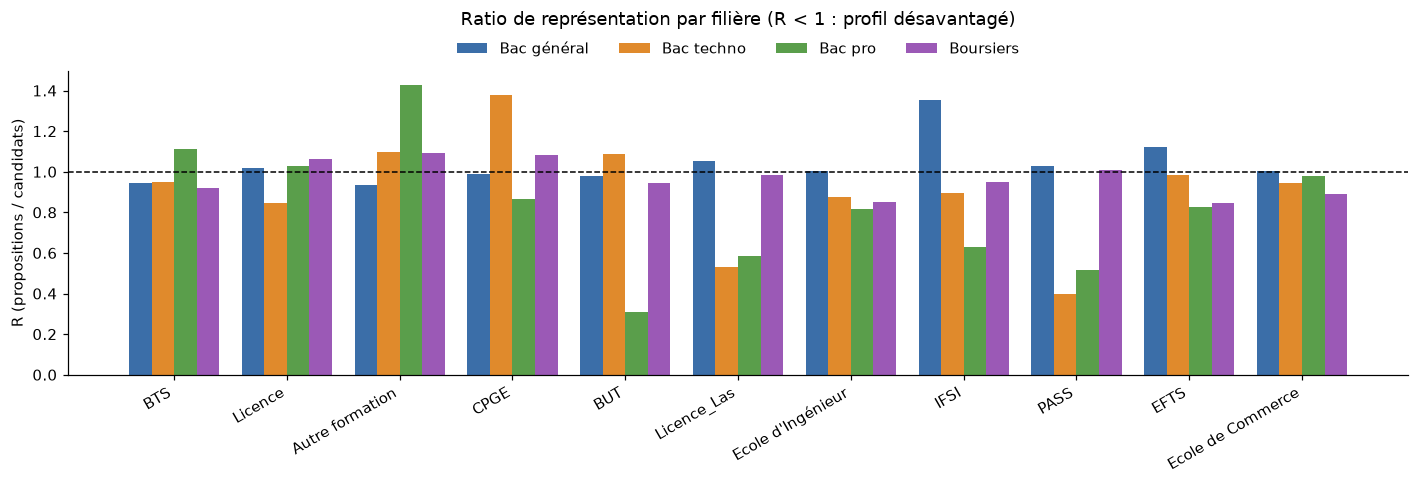

In [7]:
filieres = R_filiere.drop("TOTAL").index
x = np.arange(len(filieres))
w = 0.2
couleurs = {"Bac général": "#3b6ea8", "Bac techno": "#e08a2c", "Bac pro": "#5a9e4b", "Boursiers": "#9b59b6"}

fig, ax = plt.subplots(figsize=(13, 4.5))
for i, (profil, c) in enumerate(couleurs.items()):
    ax.bar(x + (i - 1.5) * w, R_filiere.loc[filieres, profil], w, label=profil, color=c)
ax.axhline(1, color="black", lw=1, ls="--")
ax.set_xticks(x, filieres, rotation=30, ha="right")
ax.set_ylabel("R (propositions / candidats)")
ax.set_title("Ratio de représentation par filière (R < 1 : profil désavantagé)", pad=30)
ax.legend(ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
fig.tight_layout()

### Tests du χ²

Pour chaque filière, on teste l'indépendance entre le type de bac et le fait de recevoir une proposition, avec un tableau de contingence `type de bac × (proposition / pas de proposition)`. Même chose pour boursier / non boursier.

Avec des centaines de milliers de vœux, presque tous les écarts sont « significatifs » : on regarde donc aussi la **taille de l'effet** avec le V de Cramér (≈ 0,1 faible, ≈ 0,3 moyen, ≥ 0,5 fort).

In [8]:
def chi2_test(data, profils):
    cand = np.array([data[f"cand_{p}"].sum() for p in profils])
    prop = np.array([data[f"prop_{p}"].sum() for p in profils])
    table = np.column_stack([prop, np.clip(cand - prop, 0, None)])
    chi2, p, ddl, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.sum() * (min(table.shape) - 1)))
    return chi2, p, v

def tests_par_filiere(data):
    lignes = []
    for fil, g in data.groupby("filiere"):
        chi2_b, p_b, v_b = chi2_test(g, ["G", "T", "P"])
        # boursiers vs non boursiers
        g2 = g.assign(cand_NB=g[["cand_G", "cand_T", "cand_P"]].sum(axis=1) - g["cand_B"],
                      prop_NB=g[["prop_G", "prop_T", "prop_P"]].sum(axis=1) - g["prop_B"])
        chi2_s, p_s, v_s = chi2_test(g2, ["B", "NB"])
        lignes.append({"filiere": fil, "χ² bac": chi2_b, "p bac": p_b, "V bac": v_b,
                       "χ² boursiers": chi2_s, "p boursiers": p_s, "V boursiers": v_s})
    return pd.DataFrame(lignes).set_index("filiere").sort_values("V bac", ascending=False)

tests = tests_par_filiere(df)
tests.style.format({"χ² bac": "{:,.0f}", "χ² boursiers": "{:,.0f}", "p bac": "{:.1e}", "p boursiers": "{:.1e}",
                    "V bac": "{:.3f}", "V boursiers": "{:.3f}"})

,χ² bac,p bac,V bac,χ² boursiers,p boursiers,V boursiers
filiere,,,,,,
IFSI,"27,882",0.0e+00,0.204,340,7.8e-76,0.023
Licence_Las,"4,316",0.0e+00,0.111,10,2.0e-03,0.005
EFTS,117,4.2e-26,0.082,55,1.0e-13,0.056
BUT,"5,465",0.0e+00,0.080,306,1.4e-68,0.019
Autre formation,"2,533",0.0e+00,0.070,256,1.4e-57,0.022
PASS,"3,115",0.0e+00,0.063,4,3.8e-02,0.002
BTS,"4,344",0.0e+00,0.054,"2,558",0.0e+00,0.042
Licence,"5,511",0.0e+00,0.053,"2,298",0.0e+00,0.034
CPGE,"2,176",0.0e+00,0.049,395,5.7e-88,0.021


**Lecture :** les p-values sont quasiment toutes nulles à cause de la taille de l'échantillon. Les V de Cramér permettent de classer les filières selon l'intensité de l'association entre profil et proposition. C'est un point à discuter dans l'analyse critique : la significativité statistique ne suffit pas, il faut regarder l'ampleur des écarts.

## 4. Les bacheliers généraux désavantagés en BTS et BUT

Approche symétrique : dans les formations techniques, ce sont parfois les bacheliers généraux qui reçoivent proportionnellement moins de propositions.

In [9]:
techno = df[df["filiere"].isin(["BTS", "BUT"])]
R_spe = techno.groupby(["filiere", "specialite"]).apply(ratio_R, include_groups=False)
R_spe["Formations"] = techno.groupby(["filiere", "specialite"]).size()
R_spe["Candidats généraux"] = techno.groupby(["filiere", "specialite"])["cand_G"].sum()
R_spe = R_spe[(R_spe["Candidats généraux"] >= 300)]
R_spe.sort_values("Bac général").head(15).style.format("{:.2f}", subset=list(NOMS_PROFILS.values())) \
    .background_gradient(cmap="RdBu", vmin=0.4, vmax=1.6, subset=list(NOMS_PROFILS.values()))

Attention : certaines spécialités reposent sur peu de formations (colonne *Formations*). Leurs ratios sont à interpréter avec prudence.

## 5. Dimension géographique

### 5.1 Ratio `R` par région

Text(0.5, 0.98, 'Ratio de représentation par région et par filière (cases vides : moins de 100 candidats du profil)')

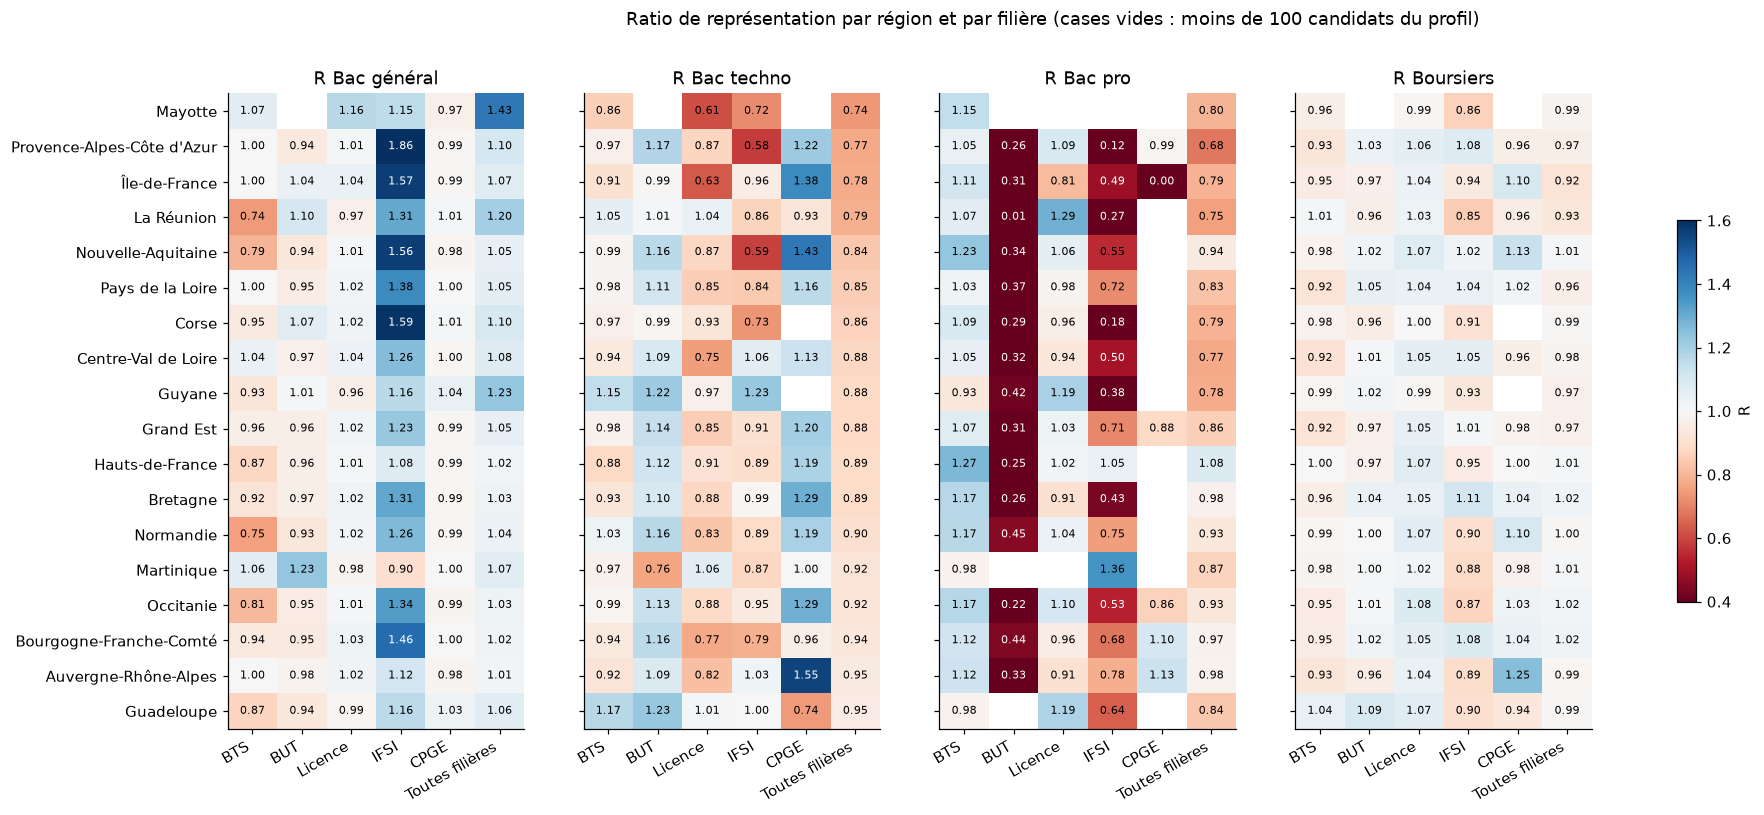

In [10]:
MIN_CANDIDATS_CASE = 100  # effectif minimal du profil pour afficher une case de la heatmap
FILIERES_CIBLES = ["BTS", "BUT", "Licence", "IFSI", "CPGE"]

regions_ok = df.groupby("region").size()
regions_ok = regions_ok[regions_ok >= MIN_FORMATIONS_REGION].index
dfr = df[df["region"].isin(regions_ok) & (df["zone"] != "Autre")]  # on écarte l'étranger et les COM

def matrice_regions(code_profil):
    # R par région × filière, masqué quand le profil compte trop peu de candidats
    profil = NOMS_PROFILS[code_profil]
    cols = {}
    for fil in FILIERES_CIBLES + ["Toutes filières"]:
        sous = dfr if fil == "Toutes filières" else dfr[dfr["filiere"] == fil]
        r = sous.groupby("region").apply(ratio_R, include_groups=False)[profil]
        n = sous.groupby("region")[f"cand_{code_profil}"].sum()
        cols[fil] = r.where(n >= MIN_CANDIDATS_CASE)
    return pd.DataFrame(cols)

# même ordre de régions pour les 4 profils : trié selon le R des bacs techno, toutes filières
ordre = matrice_regions("T")["Toutes filières"].sort_values().index

fig, axes = plt.subplots(1, 4, figsize=(20, 7.5), sharey=True)
for ax, code_p in zip(axes, PROFILS):
    m = matrice_regions(code_p).loc[ordre]
    im = ax.imshow(m.values, cmap="RdBu", vmin=0.4, vmax=1.6, aspect="auto")
    ax.set_xticks(range(m.shape[1]), m.columns, rotation=30, ha="right")
    ax.set_yticks(range(m.shape[0]), m.index)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            v = m.iat[i, j]
            if pd.notna(v):
                ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if abs(v - 1) > 0.45 else "black")
    ax.set_title(f"R {NOMS_PROFILS[code_p]}")
fig.colorbar(im, ax=axes, shrink=0.6, label="R")
fig.suptitle(f"Ratio de représentation par région et par filière (cases vides : moins de {MIN_CANDIDATS_CASE} candidats du profil)")

### 5.2 Île-de-France, province et outre-mer

In [11]:
zones = df[df["zone"] != "Autre"]
R_zone = pd.concat({fil: table_R(zones[zones["filiere"] == fil], "zone") for fil in ["BTS", "BUT", "Licence", "IFSI"]}
                   | {"Toutes filières": table_R(zones, "zone")})
R_zone.style.format("{:.2f}", subset=list(NOMS_PROFILS.values())).format("{:.0f}", subset=["Formations"]) \
    .background_gradient(cmap="RdBu", vmin=0.4, vmax=1.6, subset=list(NOMS_PROFILS.values()))

### 5.3 Recrutement local

Part des admis néo-bacheliers issus de la même académie que la formation. Pour l'Île-de-France, on utilise la colonne où les académies de Paris, Créteil et Versailles sont regroupées (sinon la part locale est artificiellement basse).

zone,Outre-mer (DROM),Province,Île-de-France
filiere,,,
Licence,88.0,77.0,81.0
PASS,91.0,85.0,91.0
Licence_Las,85.0,81.0,92.0
BUT,92.0,72.0,91.0
BTS,95.0,84.0,94.0
CPGE,97.0,69.0,77.0
IFSI,95.0,80.0,89.0


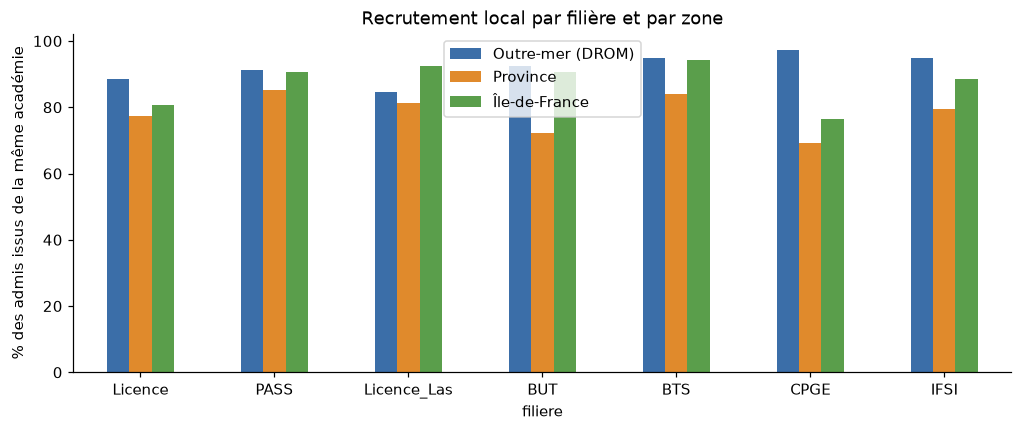

In [12]:
df["adm_local"] = np.where(df["zone"] == "Île-de-France", df["adm_meme_acad_idf"], df["adm_meme_acad"])
local = zones.assign(adm_local=df["adm_local"]).groupby(["filiere", "zone"])[["adm_local", "adm_neo"]].sum()
local = (local["adm_local"] / local["adm_neo"] * 100).unstack("zone")
local = local.loc[["Licence", "PASS", "Licence_Las", "BUT", "BTS", "CPGE", "IFSI"]]

ax = local.plot.bar(figsize=(11, 4), color=["#3b6ea8", "#e08a2c", "#5a9e4b"], rot=0)
ax.set_ylabel("% des admis issus de la même académie")
ax.set_title("Recrutement local par filière et par zone")
ax.legend(title=None)
local.round(0)

## 6. Cartes

### 6.1 Carte des régions (France métropolitaine)

Le fond de carte ne couvre que la métropole : les DROM sont présentés dans le tableau de la section 5.2.

Text(0.5, 0.98, 'Ratio de représentation par région (bleu : favorisé, rouge : désavantagé)')

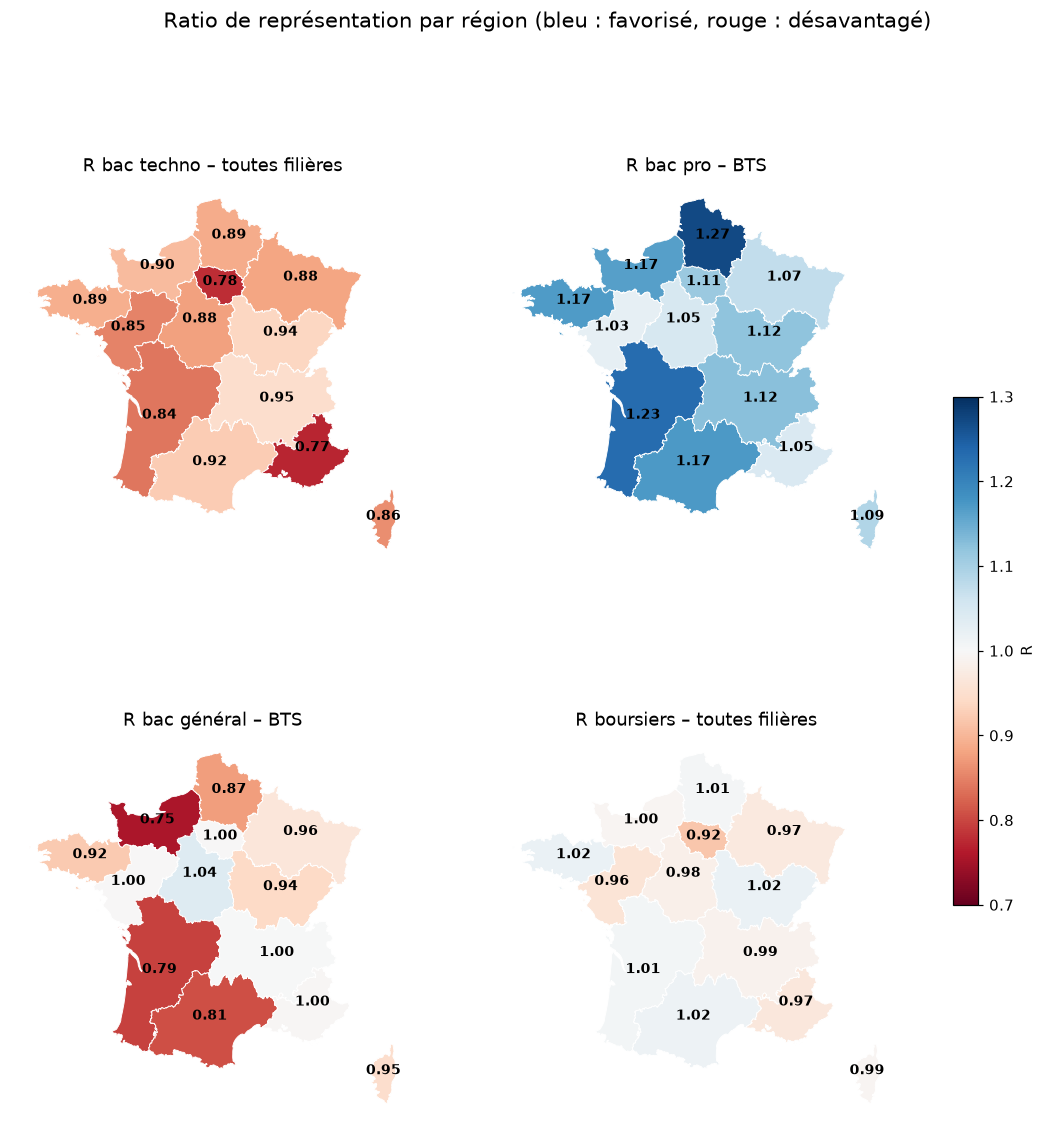

In [13]:
regions_geo = gpd.read_file(GEOJSON)

cartes = [
    ("Bac techno", None, "R bac techno – toutes filières"),
    ("Bac pro", "BTS", "R bac pro – BTS"),
    ("Bac général", "BTS", "R bac général – BTS"),
    ("Boursiers", None, "R boursiers – toutes filières"),
]

# Échelle commune aux 4 cartes pour qu'elles soient comparables entre elles
VMIN, VMAX = 0.7, 1.3

fig, axes = plt.subplots(2, 2, figsize=(13, 12))
for ax, (profil, filiere, titre) in zip(axes.flat, cartes):
    data = df if filiere is None else df[df["filiere"] == filiere]
    valeurs = table_R(data, "region")[profil].rename("R")
    carte = regions_geo.merge(valeurs, left_on="nom", right_index=True, how="left")
    carte.plot(column="R", cmap="RdBu", vmin=VMIN, vmax=VMAX, ax=ax, edgecolor="white", linewidth=0.6)
    for _, r in carte.iterrows():
        pt = r.geometry.representative_point()
        ax.annotate(f"{r['R']:.2f}", (pt.x, pt.y), ha="center", fontsize=9, fontweight="bold")
    ax.set_title(titre)
    ax.set_axis_off()
sm = plt.cm.ScalarMappable(cmap="RdBu", norm=plt.Normalize(VMIN, VMAX))
fig.colorbar(sm, ax=axes, shrink=0.5, label="R")
fig.suptitle("Ratio de représentation par région (bleu : favorisé, rouge : désavantagé)", fontsize=14)

### 6.2 Carte interactive des formations

Chaque point est une formation, coloré selon `R` pour le profil et la filière choisis. Seules les formations avec au moins `MIN_CANDIDATS` candidats du profil sont affichées. Changez `PROFIL` et `FILIERE` pour explorer (aperçu de la démo).

In [14]:
PROFIL = "P"        # G, T, P ou B
FILIERE = "BTS"     # None pour toutes les filières

def R_formations(data, p):
    # R de chaque formation pour le profil p
    tot_c = data[["cand_G", "cand_T", "cand_P"]].sum(axis=1)
    tot_p = data[["prop_G", "prop_T", "prop_P"]].sum(axis=1)
    part_c = data[f"cand_{p}"] / tot_c
    part_p = data[f"prop_{p}"] / tot_p
    r = part_p / part_c
    return r.where((data[f"cand_{p}"] >= MIN_CANDIDATS) & (tot_p > 0))

sel = df if FILIERE is None else df[df["filiere"] == FILIERE]
sel = sel.assign(R=R_formations(sel, PROFIL)).dropna(subset=["R", "lat", "lon"])
print(f"{len(sel)} formations affichées")

fig = px.scatter_map(
    sel, lat="lat", lon="lon", color="R", color_continuous_scale="RdBu", range_color=(0, 2),
    hover_name="etablissement",
    hover_data={"specialite": True, "commune": True, "R": ":.2f", f"cand_{PROFIL}": True, f"prop_{PROFIL}": True,
                "lat": False, "lon": False},
    zoom=4.3, center={"lat": 46.6, "lon": 2.4}, height=650,
    title=f"R {NOMS_PROFILS[PROFIL]} – {FILIERE or 'toutes filières'} (par formation)",
)
fig.update_traces(marker={"size": 7, "opacity": 0.8})
fig.show()

5274 formations affichées


## 7. Premiers enseignements

- **Effet « bac adapté à la filière » :** les bacs pro sont favorisés en BTS (R ≈ 1,11) et les bacs techno en BUT (R ≈ 1,09), ce qui correspond aux quotas. À l'inverse, les bacheliers généraux sont désavantagés dans plusieurs spécialités de BTS et de BUT.
- **Filières où les bacs techno et pro sont désavantagés :** licences d'accès santé (LAS), PASS et IFSI pour les bacs pro, alors que l'IFSI leur est ouvert.
- **Boursiers :** R proche de 1 dans presque toutes les filières et régions, ce qui suggère que le quota boursiers fonctionne. L'Île-de-France fait exception.
- **Territoire :** l'Île-de-France est la région la moins favorable aux bacs techno et pro, surtout en licence. En BTS, l'avantage des bacs pro varie fortement selon la région. Le BUT est homogène partout et peut servir de groupe témoin.
- **Recrutement très local :** la grande majorité des admis viennent de l'académie de la formation.

**Prochaines étapes :** régression linéaire multiple sur le R des formations (filière, sélectivité, statut, tension, région, quota), ANOVA / Kruskal-Wallis entre régions, et outil de démonstration.

**Limites à garder en tête :** pas de niveau scolaire des candidats, données en vœux et non en individus, une seule session, petits effectifs dans certaines régions et spécialités.